# 1. Multimodal
사람은 사진만 보거나 글만 읽지 않는다. 눈으로 보고, 말을 듣고, 글을 읽고, 상황을 함께 해석한다. 멀티모달도 이와 비슷하게 서로 다른 형태의 정보를 함께 다룬다.

- 이미지: 픽셀, 사물, 색, 위치, 장면
- 텍스트: 단어, 문장, 의미, 질문
- 오디오: 음성, 소리, 음악
- 비디오: 이미지의 시간적 변화 + 경우에 따라 오디오

### Multimodal Learning
- Multimodal Learning은 서로 다른 여러 모달리티의 데이터를 함께 학습하는 방식입니다. 
- 예를 들어 이미지와 텍스트를 동시에 입력으로 받아 장면을 설명하거나, 영상과 음성을 함께 활용해 감정을 인식하는 모델이 이에 해당합니다. 
- 각 모달리티가 가진 상호보완적인 정보를 결합함으로써 단일 모달리티보다 더 풍부한 표현과 높은 성능을 기대할 수 있습니다. 
- 최근에는 비전과 언어를 결합한 모델들이 대표적인 성공 사례로 주목받고 있습니다

멀티모달 모델은 서로 다른 데이터를 어떻게 연결할 것인가를 해결하는 모델

```
(이미지 > Vision Encoder > 이미지 표현)
(텍스트 > Text Encoder> 텍스트 표현)

>> 서로 의미를 연결
```

# 2. CLIP
- CLIP은 이미지와 텍스트를 같은 의미 공간으로 정렬하기 위해 대비 학습(contrastive learning)을 사용하는 대표적인 Pretrained Vision–Language 모델입니다. 
- 이미지 인코더와 텍스트 인코더를 각각 학습시킨 뒤, 올바른 이미지–텍스트 쌍은 임베딩 공간에서 가깝게, 관련 없는 쌍은 멀어지도록 학습함으로써 두 모달리티 간 의미적 대응 관계를 형성합니다. 
- 이 구조 덕분에 별도의 태스크별 학습 없이도 텍스트로 정의한 클래스 설명만으로 이미지를 분류하는 zero-shot 분류가 가능하며, 이미지–텍스트 검색(Text-to-Image, Image-to-Text Retrieval)에 특히 강점을 보입니다. 
- 다만 생성 능력은 없고, 주로 “이해와 정렬”에 초점이 맞춰진 모델이라는 특징을 가집니다. 
- [[논문](https://arxiv.org/pdf/2103.00020)]

```
이미지 > Vision Encoder(ResNet/ViT) > image embedding
                                                        > cosine similarity
문장 > Text Transformer > text embedding
```

두 벡터를 L2정규화하면 내적이 Cosine 유사도와 같아진다.

- Encoder: 원본 데이터를 모델이 계산하기 좋은 숫자 특징으로 바꾸는 부분. 예) 이미지 인코더는 사진을, 텍스트 인코더는 문장을 벡터로 바꿈
- Embedding: 토큰화된 데이터의 의미를 숫자 배열, 즉 벡터로 표현한 것. 비슷한 의미를 가진 데이터가 한 방향에 놓이도록 학습]
- Projection: 이미지 인코더와 텍스트 인코더가 만든 서로 다른 특징을 같은 차원의 공통 공간으로 옮기는 변환
- Similarity: 두 벡터가 의미적으로 얼마나 가까운지 나타내는 값

### Contrastive Learning
한 batch에 이미지 4장과 각 이미지의 설명 4개가 있음
```
            문장1   문장2   문장3   문장4

이미지1      높음    낮음    낮음    낮음
이미지2      낮음    높음    낮음    낮음
이미지3      낮음    낮음    높음    낮음
이미지4      낮음    낮음    낮음    높음
```
- 정답 쌍은 대각선. 학습은 대각선 점수를 높이고, 나머지를 낮추는 방향으로 진행. 
- CLIP은 이미지 > 텍스트 검색 & 텍스트 > 이미지 검색을 모두 수행할 수 있음
---

- 고양이 사진: "a photo of a cat" (가깝게 학습)
- 고양이 사진: "a photo of a truck" (멀게 학습)
- 고양이 사진: "a photo of a banana" (멀게 학습)
> 매우 많은 이미지-텍스트 쌍으로 반복하면 모델은 단순 클래스 번호가 아니라 시각적 특징과 언어 의미의 관계를 학습하게 됨

### Zero-shot 분류
1. 후보 클래스 이름을 문장으로 만듦. 예) "a photo of a cat"
2. 후보 문장들의 텍스트 임베딩을 만듦
3. 입력 이미지 임베딩과 각 텍스트 임베딩의 유사도를 비교함
4. 가장 유사한 텍스트를 예측 클래스로 사용함

- >shot은 새로운 작업에서 제공하는 학습 예제 수. 예) Zero-shot은 해당 작업을 위해 정답 예제를 새로 주고 재학습하지 않은 상태에서 수행하는 뜻. 
- >CLIP에서는 클래스 이름을 자연어 prompt로 만들어 비교하기 때문에 별도의 classifier 학습 없이 새로운 후보를 비교할 수 있음

In [12]:
import random
import io
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from datasets import load_dataset
from transformers import AutoProcessor, CLIPModel

SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


In [13]:
MODEL_ID = "openai/clip-vit-base-patch32"
DATASET_ID = "clip-benchmark/wds_imagenetv2"
SAMPLE_SIZE = 10

# AutoProcessor: 이미지 리사이즈/정규화와 텍스트 토큰화를 모델에 맞게 처리
# processor: 모델은 PIL 이미지나 문자열을 그대로 계산하지 못함. AutoProcessor는 모델 앞에서 입력을 모델 형식으로 바꿔주는 전처리 담당자.
"""
이미지 > resize > pixel 변환 > normalize  
                                            > 모델 입력 Tensor
문장 > tokenize > token id 변환  
"""
processor = AutoProcessor.from_pretrained(MODEL_ID)

# 이미지 인코더와 텍스트 인코더가 함께 들어있는 CLIP 본체
model = CLIPModel.from_pretrained(MODEL_ID).to(DEVICE)
model.eval()  # 테스트 모드로 변경

print("CLIP projection dim:", model.config.projection_dim)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 12860.02it/s]


CLIP projection dim: 512


In [14]:
dataset = load_dataset(DATASET_ID, split="test")
subset = dataset.shuffle(seed=SEED).select(range(SAMPLE_SIZE))

print(subset)
print("columns:", subset.column_names)

Dataset({
    features: ['__key__', '__url__', 'cls', 'webp'],
    num_rows: 10
})
columns: ['__key__', '__url__', 'cls', 'webp']


In [15]:
# 입력 이미지의 저장 형태에 따라 PIL 이미지로 변환
def to_pil(x):
    # 이미 PIL 이미지라면 RGB 3채널로 통일
    if isinstance(x, Image.Image):
        return x.convert("RGB")

    # 딕셔너리 안에 이미지의 바이너리 데이터가 들어 있는 경우
    if isinstance(x, dict) and x.get("bytes") is not None:
        # BytesIO: 바이트 데이터를 메모리 안의 파일처럼 다루게 함
        # Image.open(): 이미지로 읽기
        return Image.open(io.BytesIO(x["bytes"])).convert("RGB")

    # 문자열이라면 이미지 파일 경로로 간주하여 읽기
    if isinstance(x, str):
        return Image.open(x).convert("RGB")

    # 위 세 가지에 해당하지 않으면 오류 발생
    raise TypeError(f"지원하지 않는 이미지 타입: {type(x)}")


# subset.column_names: 데이터셋의 열 이름 목록
# "webp" 열이 있으면 사용하고, 없으면 "image" 열 사용
image_col = "webp" if "webp" in subset.column_names else "image"

# "cls" 열이 있으면 사용하고, 없으면 "label" 열 사용
label_col = "cls" if "cls" in subset.column_names else "label"

# 이미지 열의 값을 하나씩 RGB PIL 이미지로 변환하여 리스트에 저장
images = [to_pil(x) for x in subset[image_col]]

# 정답 라벨을 정수로 변환하여 리스트에 저장
labels = [int(x) for x in subset[label_col]]

# 정답 클래스 번호 목록 출력
print(labels)

[256, 661, 452, 448, 231, 528, 208, 985, 482, 475]


In [16]:
try:
    from torchvision.models import ResNet50_Weights
    imagenet_names = ResNet50_Weights.DEFAULT.meta["categories"]
except Exception as e:
    raise RuntimeError(
        "ImageNet 클래스 이름을 불러오지 못했습니다. torchvision을 설치하거나 기존 classnames.txt를 사용하세요."
    ) from e

label_names = [imagenet_names[i] for i in labels]
text_prompts = [f"a photo of a {name}" for name in label_names]

for i, (name, prompt) in enumerate(zip(label_names, text_prompts)):
    print(f"{i:02d} | {name:25s} | {prompt}")

00 | Newfoundland              | a photo of a Newfoundland
01 | Model T                   | a photo of a Model T
02 | bonnet                    | a photo of a bonnet
03 | birdhouse                 | a photo of a birdhouse
04 | collie                    | a photo of a collie
05 | dial telephone            | a photo of a dial telephone
06 | Labrador retriever        | a photo of a Labrador retriever
07 | daisy                     | a photo of a daisy
08 | cassette player           | a photo of a cassette player
09 | car mirror                | a photo of a car mirror


In [17]:
# 이미지와 텍스트를 모델이 입력받을 수 있는 형태로 전처리
inputs = processor(
    images=images,       # PIL 이미지 목록 → 크기 조절·정규화 등
    text=text_prompts,   # 후보 설명 문장 목록 → 토큰으로 변환
    padding=True,        # 문장마다 다른 토큰 길이를 패딩으로 맞춤
    return_tensors="pt"  # 결과를 PyTorch Tensor로 반환
).to(DEVICE)             # 입력 Tensor들을 GPU로 이동


# 추론 전용 모드: 기울기 기록 등을 생략하여 계산 부담을 줄임
# model.eval()은 별도로 호출해야 함
with torch.inference_mode():
    # inputs 안의 값들을 키워드 인자로 풀어서 모델에 전달
    # 예: model(pixel_values=..., input_ids=..., attention_mask=...)
    outputs = model(**inputs)

# 이미지 인코더에서 얻은 이미지별 임베딩
# shape: (이미지 수, 임베딩 차원)
image_features = outputs.image_embeds

# 텍스트 인코더에서 얻은 후보 문장별 임베딩
# shape: (후보 문장 수, 임베딩 차원)
text_features = outputs.text_embeds

# 반환된 자료형 확인: 일반적으로 torch.Tensor
print("image_features type :", type(image_features))
print("text_features type  :", type(text_features))

# 이미지 수와 문장 수는 달라도, 비교할 임베딩 차원은 같음
print("image_features shape:", image_features.shape)
print("text_features shape :", text_features.shape)

image_features type : <class 'torch.Tensor'>
text_features type  : <class 'torch.Tensor'>
image_features shape: torch.Size([10, 512])
text_features shape : torch.Size([10, 512])


### L2정규화와 Cosine 유사도
- 벡터의 길이를 1로 만들면 두 벡터의 내적은 Cosine 유사도가 됨
- Cosine 유사도가 1에 가까울수록 방향이 비슷함 > 의미적으로 더 잘 맞음
- 0에 가까움 > 관련성이 약함
- 음수 > 방향이 반대인 경향

> CLIP의 raw logit에는 학습된 temperature(logit_scale)가 추가되지만 순수 Cosine 유사도만 사용

### L2 정규화를 왜 하나?
- 벡터의 크기 자체보다 방향, 의미적 방향을 비교하기 위해서
- PyTorch의 F.normalize(..., p=2)는 각 벡터의 길이를 1로 만듦. 두 단위의 내적이 Cosine 유사도와 같아짐
```
원래 벡터: 크기(길이) + 방향을 가짐  >>  L2 normalize  >>  단위 벡터: 길이=1, 방향을 중심으로 비교
```

In [18]:
import torch.nn.functional as F

In [19]:
# L2 Normalization
image_features = F.normalize(image_features, p=2, dim=-1)
text_features = F.normalize(text_features, p=2, dim=-1)

# (이미지 수, 임베딩 차원) @ (임베딩 차원, 문장 수) > (이미지 수, 문장 수)
similarity = image_features @ text_features.T  # .T: 전치 (순서 변경)
print("similarity tensor shape: ", similarity.shape)
print(torch.round(similarity.cpu() * 1000) / 1000)
similarity_np = similarity.cpu().numpy()

similarity tensor shape:  torch.Size([10, 10])
tensor([[0.2680, 0.1930, 0.1960, 0.1820, 0.2430, 0.1910, 0.2450, 0.1730, 0.1650,
         0.1600],
        [0.1890, 0.3110, 0.2300, 0.1650, 0.2040, 0.2110, 0.2150, 0.1840, 0.1680,
         0.2200],
        [0.1800, 0.1870, 0.2460, 0.2070, 0.1920, 0.1800, 0.2080, 0.2310, 0.1660,
         0.1860],
        [0.2140, 0.2000, 0.2940, 0.3100, 0.2090, 0.2220, 0.2290, 0.2310, 0.1760,
         0.1960],
        [0.2310, 0.2080, 0.2100, 0.1690, 0.2780, 0.1840, 0.2280, 0.2280, 0.1800,
         0.1720],
        [0.1890, 0.2070, 0.2090, 0.1910, 0.1860, 0.3240, 0.1940, 0.2040, 0.2150,
         0.1970],
        [0.2140, 0.1800, 0.2090, 0.1930, 0.2440, 0.1920, 0.2390, 0.1940, 0.1570,
         0.1880],
        [0.1940, 0.1980, 0.2550, 0.2180, 0.2280, 0.2070, 0.2020, 0.3230, 0.1880,
         0.2070],
        [0.1550, 0.2190, 0.2320, 0.1910, 0.1870, 0.2450, 0.1720, 0.1950, 0.2680,
         0.2070],
        [0.1940, 0.1920, 0.2250, 0.1940, 0.2020, 0.2030, 0.212

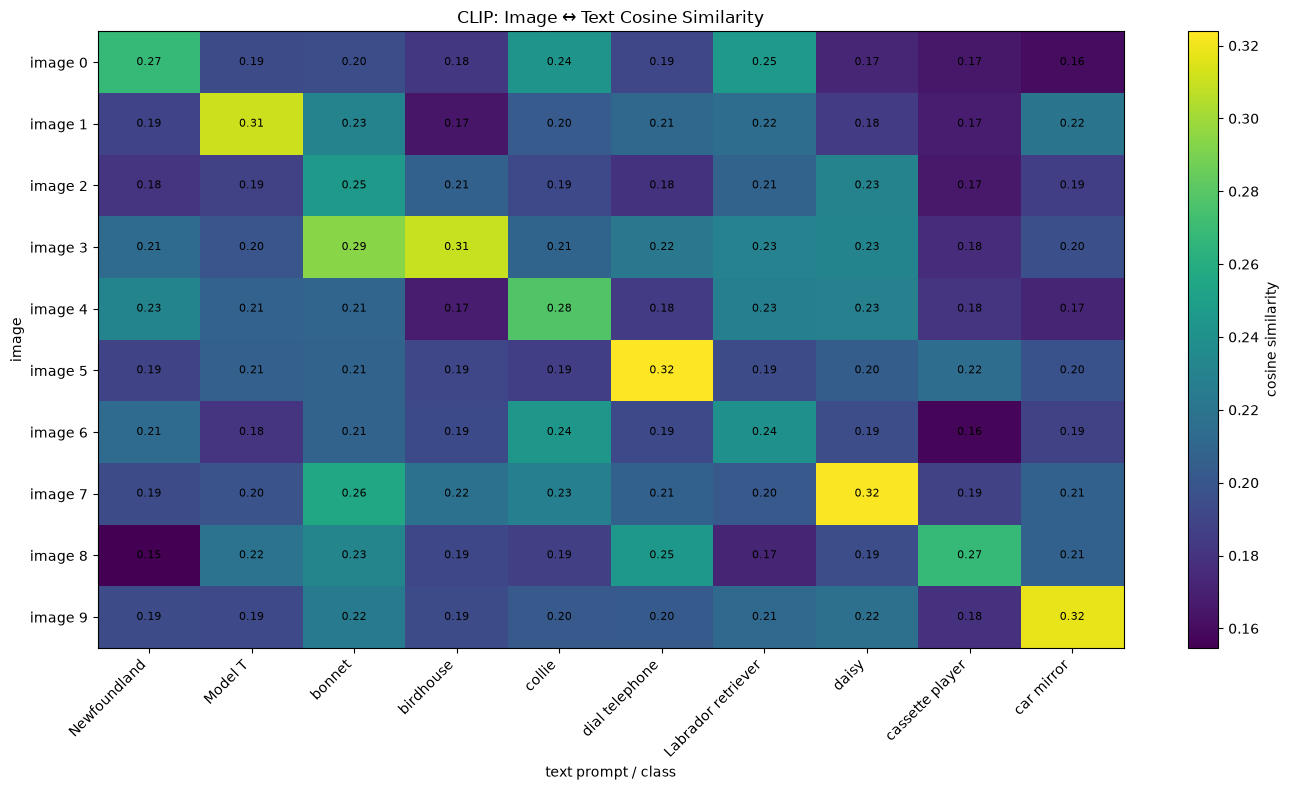

In [20]:
fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(similarity_np, aspect="auto")
fig.colorbar(im, ax=ax, label="cosine similarity")

ax.set_xticks(range(SAMPLE_SIZE))
ax.set_xticklabels(label_names, rotation=45, ha="right")
ax.set_yticks(range(SAMPLE_SIZE))
ax.set_yticklabels([f"image {i}" for i in range(SAMPLE_SIZE)])

ax.set_xlabel("text prompt / class")
ax.set_ylabel("image")
ax.set_title("CLIP: Image ↔ Text Cosine Similarity")

for i in range(SAMPLE_SIZE):
    for j in range(SAMPLE_SIZE):
        ax.text(
            j, i,
            f"{similarity_np[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

- 각 행은 이미지, 각 열은 그 이미지들에서 만든 클래스 문장
- 샘플 순서를 맞췄으므로 대각선 값이 상대적으로 높으면 정답 이미지-문장 매칭이 잘 된 것
- 하지만 일반적인 10-class 정확도라고 단정하면 안됨. 각 샘플의 정답 클래스 10개만 후보로 만들었고, 같은 클래스가 중복될 수 있음.
- 정확한 zero-shot 분류 평가를 하려면 1000개의 전체 클래스에 대해 바교를 해야 함

> CLIP은 "무엇과 관련 있는가?"에 강하지만 물체의 정확한 위치를 직접 출력하지 않고, 자연어 문장을 생성하는 것도 주목적은 아님

# 3. DINO
AI 분야에서 DINO라는 이름은 서로 다른 유명 연구에 쓰임
1. DINO (Self-Distillation with No Labels): Meta 계열의 자기지도학습 비전 표현 학습 연구. DINOv2, DINOv3 계열
2. DINO (DETR with Improve DeNoising Anchor Boxes): DETR 계열 객체 탐지 모델 [[논문](https://arxiv.org/pdf/2203.03605)]
    - DETR: Transformer와 object query를 이용해 객체 탐지를 set prediction 문제로 바꿈. anchor 설계와 NMS 중심의 전통적인 파이프라인을 크게 단순화 [[논문](https://arxiv.org/pdf/2005.12872)]
        - object query: Decoder에 들어가는 학습 가능한 객체 슬롯. 
            - 예) 100개의 query가 있다면 각 query는 이미지 특징을 보면서 "내가 찾고자 하는 객체가 있는가? 있다면 어떤 클래스이고 박스는 어디에 있나?"를 학습
        - Hungarian Matching: 동일 객체에 다한 중복 예측을 구조적으로 줄일 수 있는 탐지 목표
        - set prediction: 이미지 안에 존재하는 객체들의 집합을 예측. Hungarian Matching으로 예측과 정답의 짝을 정함
        
    - DINO (DETR 계열): DETR 계열의 느림 수렴과 query 학습 문제를 개선하기 위해 denoizing training, 더 좋은 query/reference 설계 등 사용
        - denoising training: 정답 label/box에 일부 노이즈를 넣은 query를 추가하고, 모델이 원래 정답을 복원하도록 학습
        
    - Grounding DINO: DINO 계열 detector에 언어 조건을 결합.
        - DETR: 이미지 > "객체가 어디에 있지?"
        - DINO: 이미지 > "더 안정적이고 효율적으로 객체 찾아"
        - Grounding DINO: 이미지 + 텍스트 > "이 문구가 가리키는 객체가 어디에 있지?"
        - 예) a cat. a remote control. 을 넣게되면 모델은 고정된 coco 클래스 번호만 내는 것이 아니라 텍스트 표현과 관련 있는 이미지 영역을 찾아 박스로 반환
        - 결과는 단순히 label이라는 분류 결과가 아니라, 보통 label + score + bounding box의 형태가 될 것    

In [21]:
import requests
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

MODEL_ID = "IDEA-Research/grounding-dino-tiny"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


In [23]:
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForZeroShotObjectDetection.from_pretrained(MODEL_ID).to(device)
model.eval()

Loading weights: 100%|██████████| 978/978 [00:01<00:00, 766.72it/s]


GroundingDinoForObjectDetection(
  (model): GroundingDinoModel(
    (backbone): GroundingDinoConvModel(
      (conv_encoder): GroundingDinoConvEncoder(
        (model): SwinBackbone(
          (swin): SwinModel(
            (embeddings): SwinEmbeddings(
              (patch_embeddings): SwinPatchEmbeddings(
                (projection): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
              )
              (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (encoder): SwinEncoder(
              (layers): ModuleList(
                (0): SwinStage(
                  (blocks): ModuleList(
                    (0): SwinLayer(
                      (attention): SwinAttention(
                        (q_proj): Linear(in_features=96, out_features=96, bias=True)
                        (k_proj): Linear(in_features=96, out_features=96, bias=True)
                        (v_proj): Linear(

In [ ]:
# 사용할 이미지의 인터넷 주소
image_url = "http://images.cocodataset.org/val2017/000000039769.jpg"

# requests.get(): 해당 주소에 이미지 데이터를 요청
# stream=True: 응답 본문 전체를 즉시 읽지 않고, 이후 필요할 때 읽도록 설정
# .raw: 응답 데이터를 파일처럼 읽을 수 있는 통로
# Image.open(): 해당 데이터를 PIL 이미지로 열기
# .convert("RGB"): 이미지를 빨강·초록·파랑의 3채널 형식으로 통일
image = Image.open(
    requests.get(image_url, stream=True).raw
).convert("RGB")

# 이미지에서 찾고 싶은 대상의 텍스트 목록
# 바깥 리스트: 이미지별 후보 목록
# 안쪽 리스트: 해당 이미지에서 찾을 대상들
# 여기서는 이미지 1장에서 고양이와 리모컨을 찾겠다는 의미
text_labels = [["a cat", "a remote control"]]

# 이미지와 텍스트를 모델이 받을 수 있는 숫자 데이터로 전처리
inputs = processor(
    images=image,        # 이미지 크기 조절·정규화 등을 수행
    text=text_labels,    # 텍스트를 토큰화하고 토큰 ID 등으로 변환
    return_tensors="pt"  # 결과를 PyTorch Tensor로 반환
).to(device)             # 입력 Tensor들을 지정한 장치(CPU/GPU 등)로 이동

# 입력 항목 중 shape 속성이 있는 값만 골라 크기를 출력
# k: 항목 이름. 예) "pixel_values", "input_ids"
# v: 해당 항목의 값
# inputs.items(): 이름과 값을 하나씩 꺼냄
# hasattr(v, "shape"): v에 shape 속성이 있는지 확인
# tuple(v.shape): 크기를 (1, 3, H, W) 같은 튜플로 표현
print({
    k: tuple(v.shape)
    for k, v in inputs.items()
    if hasattr(v, "shape")
})

{'input_ids': (1, 9), 'token_type_ids': (1, 9), 'attention_mask': (1, 9), 'pixel_mask': (1, 800, 1066), 'pixel_values': (1, 3, 800, 1066)}


- Logit: sigmoid/sofmax 같은 확률 변환 이전 단계의 모델 점수
- Post-processing: 모델이 원시 출력(raw value)을 threshold로 거르고, box를 원본 이미지 크기에 맞는 좌표로 변환 등의 후처리
- target_size: resize되기 전 원본 이미지의 (height, width)를 알려주어 box를 원본 좌표계로 복원하는 데 사용

In [ ]:
# 기울기 기록 없이 추론
with torch.inference_mode():
    outputs = model(**inputs)

# 점수 기준으로 후보를 고르고 원본 이미지 좌표로 변환
results = processor.post_process_grounded_object_detection(
    outputs,
    threshold=0.35,       # threshold: 객체 후보를 박스로 인정할 것인가?
    text_threshold=0.25,  # text_threshold: 이 영역과 텍스트 표현의 연결이 충분히 강한지
    target_sizes=[(image.height, image.width)],  # 원본 크기: (높이, 너비)
    text_labels=text_labels,  # 후보 텍스트. 현재 구현에서는 직접 사용하지 않음
)

# 첫 번째 이미지의 탐지 결과
result = results[0]

# text_labels 키가 없으면 labels 사용
detected_labels = result.get("text_labels", result.get("labels"))

# 탐지된 객체 수
print("detections:", len(result["boxes"]))

# 같은 객체의 bounding box, 점수, label을 함께 꺼냄
for box, score, label in zip(
    result["boxes"],
    result["scores"],
    detected_labels
):
    # 좌표를 리스트로 변환하고 소수점 첫째 자리까지 반올림
    box = [round(x, 1) for x in box.tolist()]

    # 점수를 Python 숫자로 꺼내 소수점 셋째 자리까지 출력
    print(
        f"{label} | score={score.item():.3f} | box={box}"
    )

detections: 3
a cat | score=0.487 | box=[344.5, 23.2, 637.3, 374.5]
a cat | score=0.450 | box=[12.2, 52.0, 316.9, 472.6]
a remote control | score=0.466 | box=[38.8, 70.0, 176.7, 118.1]


c:\DEV\AIML\4_MULTIMODAL\venv\Lib\site-packages\transformers\models\grounding_dino\processing_grounding_dino.py:94: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


c:\DEV\AIML\4_MULTIMODAL\venv\Lib\site-packages\transformers\models\grounding_dino\processing_grounding_dino.py:94: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


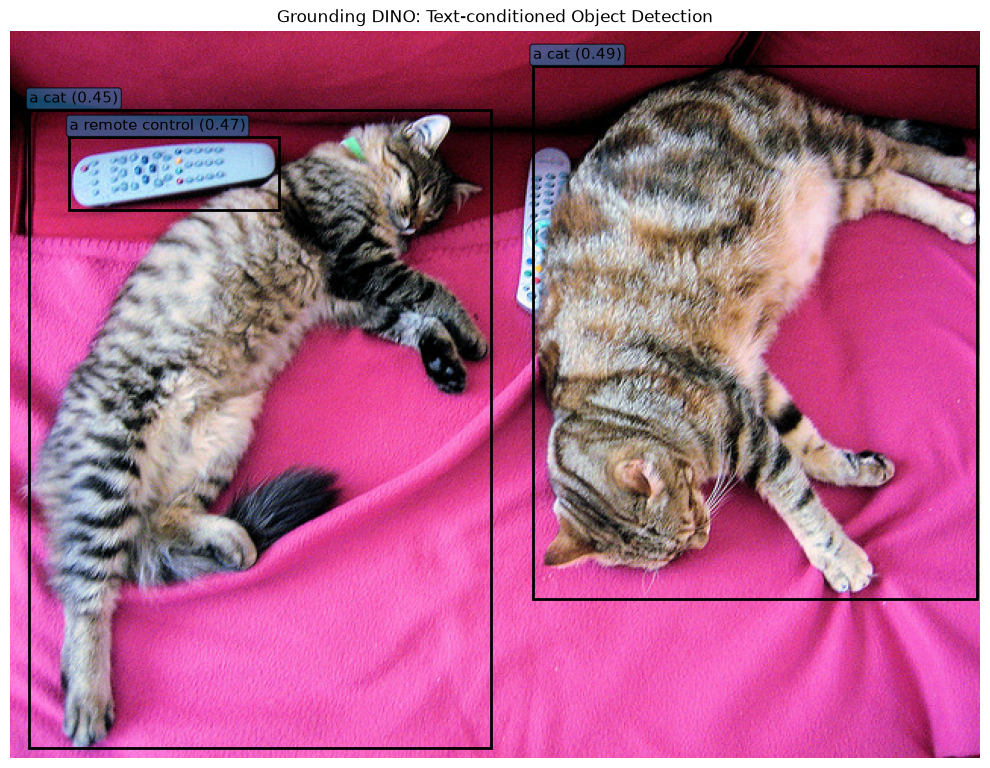

In [28]:
# threshold: 객체 후보를 박스로 인정할 것인가?
# text_threshold: 이 영역과 텍스트 표현의 연결이 충분히 강한지
# 너무 낮추면 오탐이 늘고, 너무 높이면 실제 객체도 놓칠 수 있음

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(image)

detected_labels = result.get("text_labels", result.get("labels"))

for score, box, label in zip(
    result["scores"].detach().cpu(),
    result["boxes"].detach().cpu(),
    detected_labels
):
    x1, y1, x2, y2 = box.tolist()

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        fill=False
    )
    ax.add_patch(rect)

    ax.text(
        x1,
        max(0, y1 - 5),
        f"{label} ({score.item():.2f})",
        fontsize=11,
        bbox=dict(alpha=0.6, boxstyle="round,pad=0.2")
    )

ax.axis("off")
ax.set_title("Grounding DINO: Text-conditioned Object Detection")
plt.tight_layout()
plt.show()

# 4. BLIP
- CLIP은 이미지와 텍스트를 같은 임베딩 공간에 잘 정렬하지만 기본적으로 텍스트 생성 모델은 아님
- BLIP은 이미지-텍스트 정렬뿐 아니라 이미지 캡셔닝(문장생성), 이미지-텍스트 매칭, VQA 같은 텍스트 이해/생성 작업을 함께 다루는 방향으로 발전. 웹에서 모은 이미지-텍스트 쌍의 노이즈를 그대로 믿지 않고, 모델이 캡션을 생성하고 필터링하여 학습 데이터를 개선하는 CapFit방식 [[논문](https://arxiv.org/pdf/2201.12086)]

### BLIP 구조
BLIP은 하나의 Transformer 계열을 상황에 따라 사용해 아래와 같은 특징을 가짐
- Image Encoder: 이미지를 시작 특징으로 변환
- Text Encoder: 텍스트를 읽고 이미지-텍스트 정렬/매칭에 활용
- Image-grounded Text Encoder: 이미지 특징을 cross-attention으로 보면서 다음 토큰을 생성

> "이 이미지를 문장으로 어떻게 설명할까?"를 수행할 수 있음

### Cross-Attention
- Self-Attention: 같은 입력 내부의 토큰끼리 참고
- Cross-Attention: 한 종류의 표현이 다른 종류의 표현을 참고. BLIP의 텍스트 생성기는 문장을 만들면서 이미지 특징을 cross-attention으로 바라볼 수 있음

In [29]:
import requests
import torch
from PIL import Image
from transformers import AutoProcessor, BlipForConditionalGeneration

MODEL_ID = "Salesforce/blip-image-captioning-base"  # 이미지에 cationing 달아주는 모델
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = BlipForConditionalGeneration.from_pretrained(MODEL_ID).to(device)
model.eval()

c:\DEV\AIML\4_MULTIMODAL\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kesgo\.cache\huggingface\hub\models--Salesforce--blip-image-captioning-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 473/473 [00:00<00:00, 12589.11it/s]


BlipForConditionalGeneration(
  (vision_model): BlipVisionModel(
    (embeddings): BlipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    )
    (encoder): BlipEncoder(
      (layers): ModuleList(
        (0-11): 12 x BlipEncoderLayer(
          (self_attn): BlipAttention(
            (dropout): Dropout(p=0.0, inplace=False)
            (qkv): Linear(in_features=768, out_features=2304, bias=True)
            (projection): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): BlipMLP(
            (activation_fn): GELUActivation()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=3072, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        )
      )
    )
    (post_layernorm): Laye

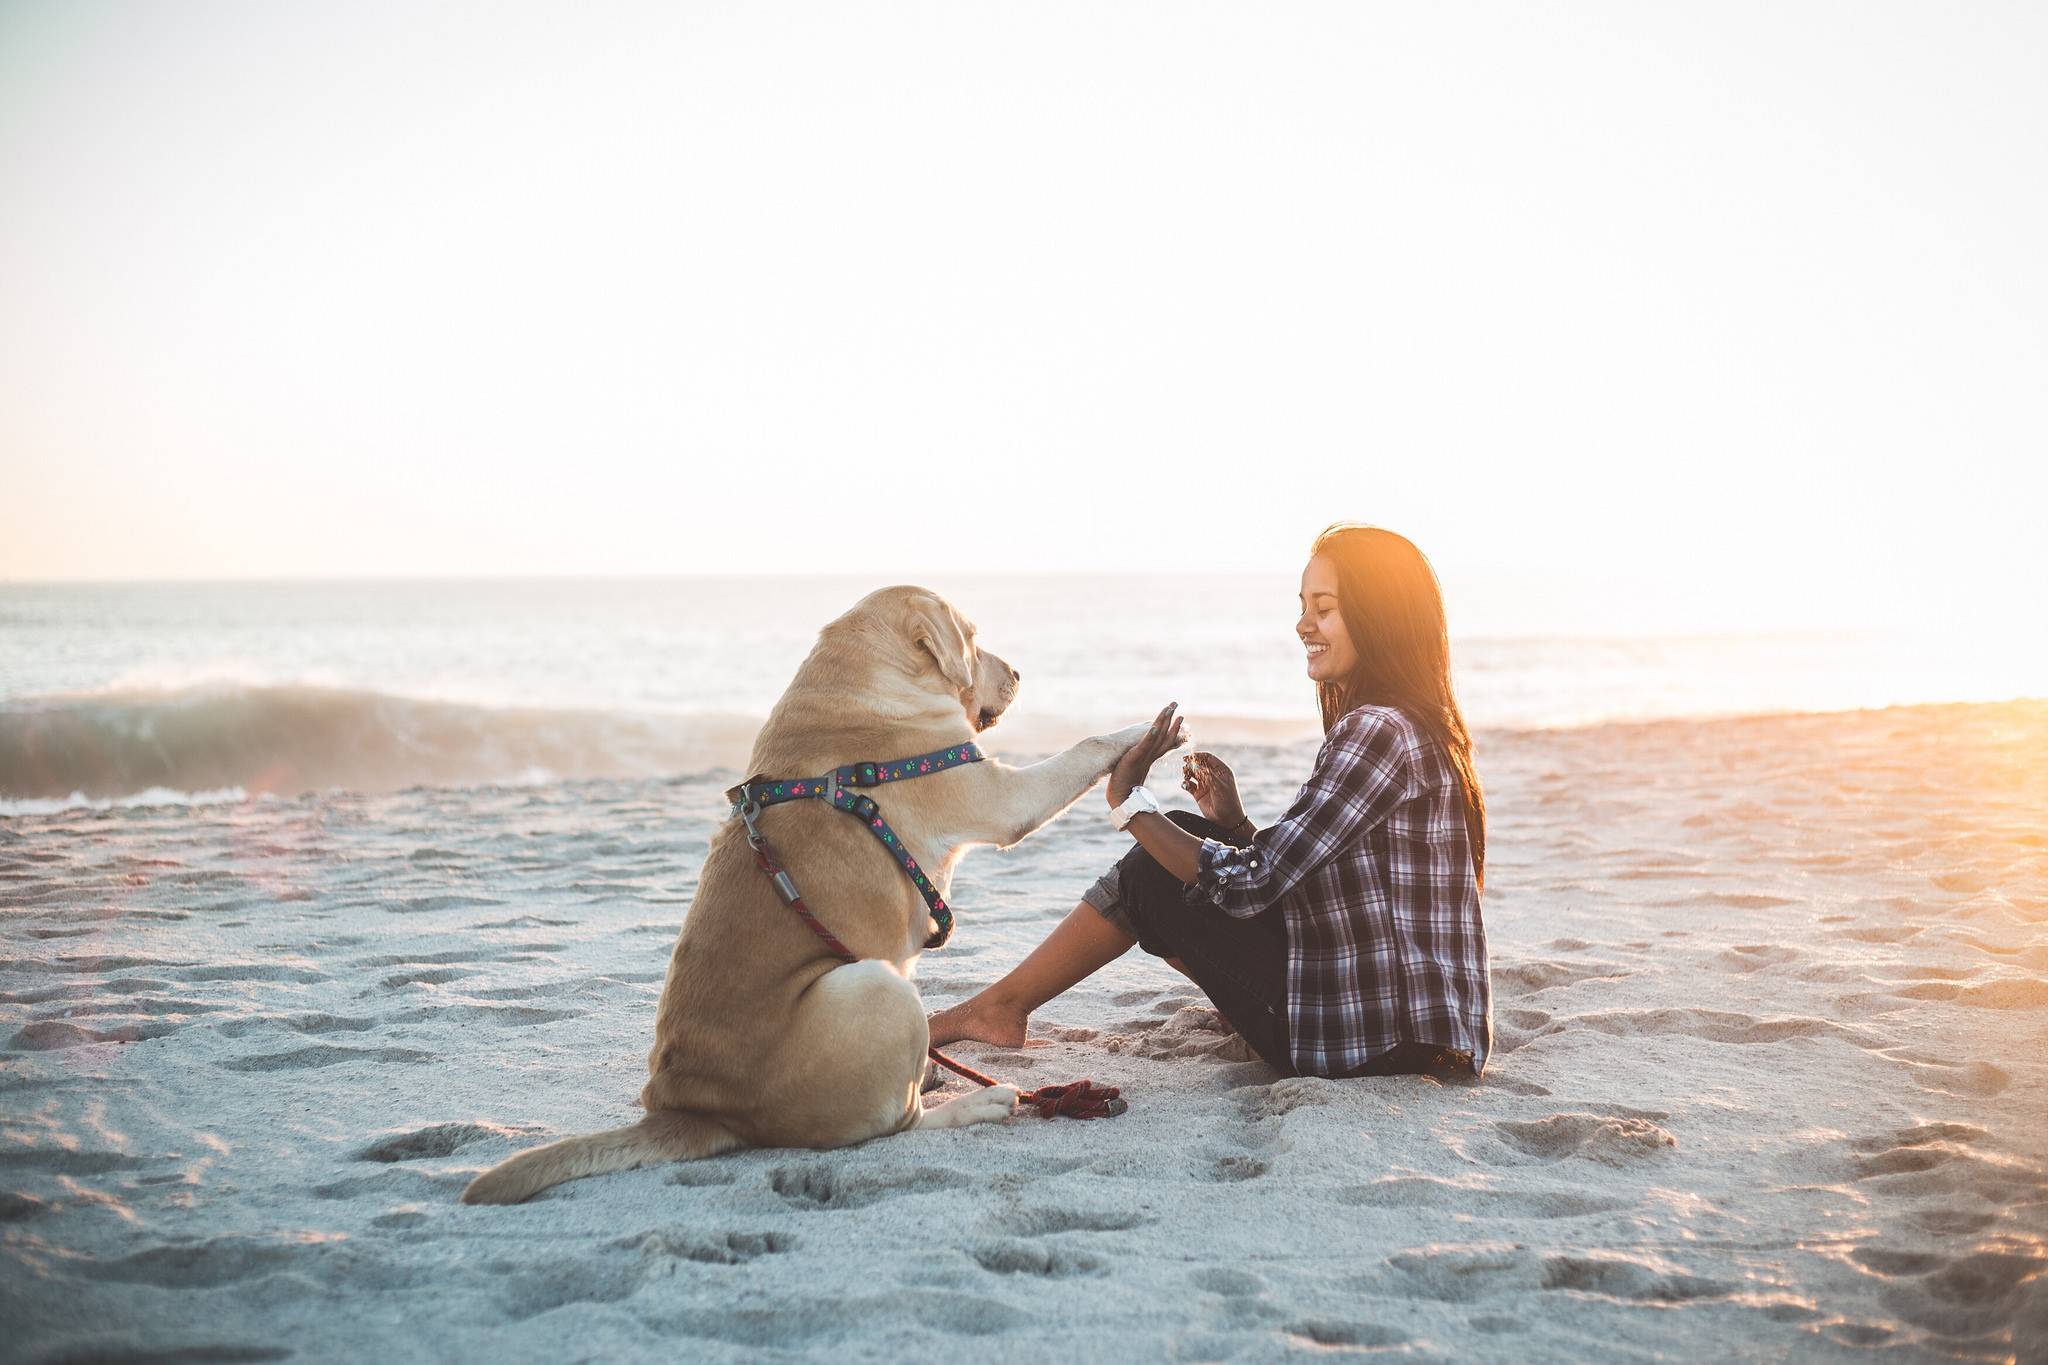

In [33]:
image_url = "https://storage.googleapis.com/sfr-vision-language-research/BLIP/demo.jpg"
image = Image.open(requests.get(image_url, stream=True).raw).convert("RGB")
display(image)

In [ ]:
# PyTorch의 tensor형으로 반환
inputs = processor(images=image, return_tensors="pt").to(device)

# 추론모드
with torch.inference_mode():  # 학습용 계산 기록 생략
    generated_ids = model.generate(**inputs, max_new_tokens=30)  # 실제 사진 설명 생성

# 토큰 ID를 문장(Caption)으로 변환하고, 특수 토큰 제외 후 첫 문장의 앞뒤 공백 제거
caption = processor.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()
print("caption:", caption)

caption: a woman sitting on the beach with her dog
